# 10 minutes to Pandas
Simply search krna h pandas google par, fir first pay jo link aye ga usko click krna h or user guide mey pandas 10 minutes parhna h us k code ko copy, paste,run, understand krna h. 

This is a short introduction to pandas, geared mainly for new users. You can see more complex recipes in the Cookbook.

Customarily, we import as follows:

In [100]:
# we import as follows
import pandas as pd
import numpy as np

# Basic data structures in pandas
pandas provides two types of classes for handling data:

Series: a one-dimensional labeled array holding data of any type
such as integers, strings, Python objects etc.

DataFrame: a two-dimensional data structure that holds data like a two-dimension array or a table with rows and columns.

# Object creation
See the Intro to data structures section.

Creating a Series by passing a list of values, letting pandas create a default RangeIndex.


In [101]:
# Creating a Series by passing a list of values, letting pandas create a default Rang
s = pd.Series([1, 3, 5, np.nan, 6, 8])
s

0    1.0
1    3.0
2    5.0
3    NaN
4    6.0
5    8.0
dtype: float64

Creating a DataFrame by passing a NumPy array with a datetime index using date_range() and labeled columns:

In [102]:
# Creating a DataFrame by passing a NumPy array with a datetime index using date_range()
# and labeled columns:
dates = pd.date_range("20130101", periods=6)
dates

DatetimeIndex(['2013-01-01', '2013-01-02', '2013-01-03', '2013-01-04',
               '2013-01-05', '2013-01-06'],
              dtype='datetime64[us]', freq='D')

In [103]:

df = pd.DataFrame(np.random.randn(6, 4), index=dates, columns=list("ABCD"))

df

,A,B,C,D
2013-01-01,0.376707,0.680972,0.235829,-0.848113
2013-01-02,0.006248,0.627224,1.017980,-0.791758
2013-01-03,-2.171135,0.363666,0.467047,0.743437
2013-01-04,-0.184315,1.847120,0.241231,1.853026
2013-01-05,-0.196291,1.176438,-0.338923,-0.459901
2013-01-06,-0.227144,-0.351231,-1.044302,0.988339


Creating a DataFrame by passing a dictionary of objects where the keys are the column labels and the values are the column values.

In [104]:
# Creating a DataFrame by passing a dictionary of objects where the keys are the column
# labels and the values are the column values.
df2 = pd.DataFrame(
    {
        "A": 1.0,
        "B": pd.Timestamp("20130102"),
        "C": pd.Series(1, index=list(range(4)), dtype="float32"),
        "D": np.array([3] * 4, dtype="int32"),
        "E": pd.Categorical(["test", "train", "test", "train"]),
        "F": "foo",
    }
)
df2

,A,B,C,D,E,F
0,1.0,2013-01-02,1.0,3,test,foo
1,1.0,2013-01-02,1.0,3,train,foo
2,1.0,2013-01-02,1.0,3,test,foo
3,1.0,2013-01-02,1.0,3,train,foo


The columns of the resulting DataFrame have different dtypes:

In [105]:
# The columns of the resulting DataFrame have different dtypes:
df2.dtypes

A           float64
B    datetime64[us]
C           float32
D             int32
E          category
F               str
dtype: object

# Viewing data
See the Essential basic functionality section.

Use DataFrame.head() and DataFrame.tail() to view the top and bottom rows of the frame respectively:

In [106]:
# Use DataFrame.head() and DataFrame.tail() to view the top and bottom rows 
# of the frame respectively:
df.head()

,A,B,C,D
2013-01-01,0.376707,0.680972,0.235829,-0.848113
2013-01-02,0.006248,0.627224,1.017980,-0.791758
2013-01-03,-2.171135,0.363666,0.467047,0.743437
2013-01-04,-0.184315,1.847120,0.241231,1.853026
2013-01-05,-0.196291,1.176438,-0.338923,-0.459901


In [107]:
df.tail(3)

,A,B,C,D
2013-01-04,-0.184315,1.847120,0.241231,1.853026
2013-01-05,-0.196291,1.176438,-0.338923,-0.459901
2013-01-06,-0.227144,-0.351231,-1.044302,0.988339


Display the DataFrame.index or DataFrame.columns:

In [108]:
df.index

DatetimeIndex(['2013-01-01', '2013-01-02', '2013-01-03', '2013-01-04',
               '2013-01-05', '2013-01-06'],
              dtype='datetime64[us]', freq='D')

In [109]:
df.columns

Index(['A', 'B', 'C', 'D'], dtype='str')

Return a NumPy representation of the underlying data with DataFrame.to_numpy() without the index or column labels:

In [110]:
df.to_numpy()

array([[ 0.37670695,  0.68097164,  0.23582896, -0.84811255],
       [ 0.00624764,  0.62722389,  1.01798022, -0.79175782],
       [-2.17113521,  0.36366591,  0.46704657,  0.74343668],
       [-0.18431522,  1.84712034,  0.24123063,  1.85302565],
       [-0.19629098,  1.17643783, -0.33892288, -0.45990052],
       [-0.22714402, -0.35123072, -1.04430184,  0.98833912]])

**Note**

NumPy arrays have one dtype for the entire array while pandas DataFrames have one dtype 
per column. When you call DataFrame.to_numpy(), pandas will find the NumPy dtype that 
can hold all of the dtypes in the DataFrame. If the common data type is object,
DataFrame.to_numpy() will require copying data.

In [111]:
df2.dtypes

A           float64
B    datetime64[us]
C           float32
D             int32
E          category
F               str
dtype: object

In [112]:
df2.to_numpy()

array([[1.0, Timestamp('2013-01-02 00:00:00'), 1.0, 3, 'test', 'foo'],
       [1.0, Timestamp('2013-01-02 00:00:00'), 1.0, 3, 'train', 'foo'],
       [1.0, Timestamp('2013-01-02 00:00:00'), 1.0, 3, 'test', 'foo'],
       [1.0, Timestamp('2013-01-02 00:00:00'), 1.0, 3, 'train', 'foo']],
      dtype=object)

describe() shows a quick statistic summary of your data:

In [113]:
df.describe()

,A,B,C,D
count,6.000000,6.000000,6.000000,6.000000
mean,-0.399322,0.724031,0.096477,0.247505
std,0.897009,0.743408,0.709621,1.109355
min,-2.171135,-0.351231,-1.044302,-0.848113
25%,-0.219431,0.429555,-0.195235,-0.708793
50%,-0.190303,0.654098,0.238530,0.141768
75%,-0.041393,1.052571,0.410593,0.927114
max,0.376707,1.847120,1.017980,1.853026


Transposing your data:

In [114]:
df.T

,2013-01-01,2013-01-02,2013-01-03,2013-01-04,2013-01-05,2013-01-06
A,0.376707,0.006248,-2.171135,-0.184315,-0.196291,-0.227144
B,0.680972,0.627224,0.363666,1.847120,1.176438,-0.351231
C,0.235829,1.017980,0.467047,0.241231,-0.338923,-1.044302
D,-0.848113,-0.791758,0.743437,1.853026,-0.459901,0.988339


DataFrame.sort_index() sorts by an axis:

In [115]:
df.sort_index(axis=1, ascending=False)

,D,C,B,A
2013-01-01,-0.848113,0.235829,0.680972,0.376707
2013-01-02,-0.791758,1.017980,0.627224,0.006248
2013-01-03,0.743437,0.467047,0.363666,-2.171135
2013-01-04,1.853026,0.241231,1.847120,-0.184315
2013-01-05,-0.459901,-0.338923,1.176438,-0.196291
2013-01-06,0.988339,-1.044302,-0.351231,-0.227144


DataFrame.sort_values() sorts by values:

In [116]:
df.sort_values(by="B")


,A,B,C,D
2013-01-06,-0.227144,-0.351231,-1.044302,0.988339
2013-01-03,-2.171135,0.363666,0.467047,0.743437
2013-01-02,0.006248,0.627224,1.017980,-0.791758
2013-01-01,0.376707,0.680972,0.235829,-0.848113
2013-01-05,-0.196291,1.176438,-0.338923,-0.459901
2013-01-04,-0.184315,1.847120,0.241231,1.853026


# Selection
**Note**

While standard Python / NumPy expressions for selecting and setting are intuitive and come in handy for interactive work, for production code, we recommend the optimized pandas data access methods, DataFrame.at(), DataFrame.iat(), DataFrame.loc() and DataFrame.iloc().

See the indexing documentation Indexing and Selecting Data and MultiIndex / Advanced Indexing.

# Getitem ([])
For a DataFrame, passing a single label selects a column and yields a Series:

In [117]:
df["A"]


2013-01-01    0.376707
2013-01-02    0.006248
2013-01-03   -2.171135
2013-01-04   -0.184315
2013-01-05   -0.196291
2013-01-06   -0.227144
Freq: D, Name: A, dtype: float64

If the label only contains letters, numbers, and underscores, you can alternatively use the column name attribute:

In [118]:
df.A

2013-01-01    0.376707
2013-01-02    0.006248
2013-01-03   -2.171135
2013-01-04   -0.184315
2013-01-05   -0.196291
2013-01-06   -0.227144
Freq: D, Name: A, dtype: float64

Passing a list of column labels selects multiple columns, which can be useful for getting a subset/rearranging:

In [119]:
df[["B", "A"]]

,B,A
2013-01-01,0.680972,0.376707
2013-01-02,0.627224,0.006248
2013-01-03,0.363666,-2.171135
2013-01-04,1.847120,-0.184315
2013-01-05,1.176438,-0.196291
2013-01-06,-0.351231,-0.227144


For a DataFrame, passing a slice : selects matching rows:

In [120]:
df[0:3]

,A,B,C,D
2013-01-01,0.376707,0.680972,0.235829,-0.848113
2013-01-02,0.006248,0.627224,1.017980,-0.791758
2013-01-03,-2.171135,0.363666,0.467047,0.743437


In [121]:
df.iloc[0:3,0:4] # iloc matlb index ko loc karne k liye

,A,B,C,D
2013-01-01,0.376707,0.680972,0.235829,-0.848113
2013-01-02,0.006248,0.627224,1.017980,-0.791758
2013-01-03,-2.171135,0.363666,0.467047,0.743437


In [122]:
df["20130102":"20130104"]

,A,B,C,D
2013-01-02,0.006248,0.627224,1.017980,-0.791758
2013-01-03,-2.171135,0.363666,0.467047,0.743437
2013-01-04,-0.184315,1.847120,0.241231,1.853026


# Selection by label
See more in Selection by Label using DataFrame.loc() or DataFrame.at().

Selecting a row matching a label:

In [ ]:
df.loc[dates[0]] # loc ka function tab lgatay hein jab hmnay apni marzi k colum lenay hu


A    0.376707
B    0.680972
C    0.235829
D   -0.848113
Name: 2013-01-01 00:00:00, dtype: float64

Selecting all rows (:) with a select column labels:

In [124]:
df.loc[:, ["A", "B"]]

,A,B
2013-01-01,0.376707,0.680972
2013-01-02,0.006248,0.627224
2013-01-03,-2.171135,0.363666
2013-01-04,-0.184315,1.847120
2013-01-05,-0.196291,1.176438
2013-01-06,-0.227144,-0.351231


For label slicing, both endpoints are included:

In [125]:
df.loc["20130102":"20130104", ["A", "B"]]

,A,B
2013-01-02,0.006248,0.627224
2013-01-03,-2.171135,0.363666
2013-01-04,-0.184315,1.847120


Selecting a single row and column label returns a scalar:

In [126]:
df.loc[dates[0], "A"]

np.float64(0.3767069508967631)

For getting fast access to a scalar (equivalent to the prior method):

In [127]:
df.at[dates[0], "A"]

np.float64(0.3767069508967631)

# Selection by position
See more in Selection by Position using DataFrame.iloc() or DataFrame.iat().

Select via the position of the passed integers:

In [128]:
df.iloc[3]

A   -0.184315
B    1.847120
C    0.241231
D    1.853026
Name: 2013-01-04 00:00:00, dtype: float64

Integer slices acts similar to NumPy/Python:

**Slicing:** slicing matlb baray data set mesay koi apni marzi ka part nikal lena usko slicing boltay hein .

In [129]:
df.iloc[3:5, 0:2]

,A,B
2013-01-04,-0.184315,1.847120
2013-01-05,-0.196291,1.176438


Lists of integer position locations:

In [130]:
df.iloc[[1, 2, 4], [0, 2]]

,A,C
2013-01-02,0.006248,1.017980
2013-01-03,-2.171135,0.467047
2013-01-05,-0.196291,-0.338923


For slicing rows explicitly:

In [131]:
df.iloc[1:3, :]

,A,B,C,D
2013-01-02,0.006248,0.627224,1.017980,-0.791758
2013-01-03,-2.171135,0.363666,0.467047,0.743437


For slicing columns explicitly:

In [132]:
df.iloc[:, 1:3]


,B,C
2013-01-01,0.680972,0.235829
2013-01-02,0.627224,1.017980
2013-01-03,0.363666,0.467047
2013-01-04,1.847120,0.241231
2013-01-05,1.176438,-0.338923
2013-01-06,-0.351231,-1.044302


For getting a value explicitly:

In [133]:
df.iloc[1, 1]

np.float64(0.627223893827526)

For getting fast access to a scalar (equivalent to the prior method):

In [134]:
df.iat[1, 1]

np.float64(0.627223893827526)

# Boolean indexing
Select rows where df.A is greater than 0.

In [135]:
df[df["A"] > 0]

,A,B,C,D
2013-01-01,0.376707,0.680972,0.235829,-0.848113
2013-01-02,0.006248,0.627224,1.017980,-0.791758


Selecting values from a DataFrame where a boolean condition is met:

In [136]:
df[df > 0]

,A,B,C,D
2013-01-01,0.376707,0.680972,0.235829,NaN
2013-01-02,0.006248,0.627224,1.017980,NaN
2013-01-03,NaN,0.363666,0.467047,0.743437
2013-01-04,NaN,1.847120,0.241231,1.853026
2013-01-05,NaN,1.176438,NaN,NaN
2013-01-06,NaN,NaN,NaN,0.988339


Using isin() method for filtering:

In [137]:
df2 = df.copy()

df2["E"] = ["one", "one", "two", "three", "four", "three"]

df2



,A,B,C,D,E
2013-01-01,0.376707,0.680972,0.235829,-0.848113,one
2013-01-02,0.006248,0.627224,1.017980,-0.791758,one
2013-01-03,-2.171135,0.363666,0.467047,0.743437,two
2013-01-04,-0.184315,1.847120,0.241231,1.853026,three
2013-01-05,-0.196291,1.176438,-0.338923,-0.459901,four
2013-01-06,-0.227144,-0.351231,-1.044302,0.988339,three


In [138]:
df2[df2["E"].isin(["two", "four"])]

,A,B,C,D,E
2013-01-03,-2.171135,0.363666,0.467047,0.743437,two
2013-01-05,-0.196291,1.176438,-0.338923,-0.459901,four


# Setting
Setting a new column automatically aligns the data by the indexes:

In [139]:
s1 = pd.Series(
   [1, 2, 3, 4, 5, 6],
   index=pd.date_range("20130102", periods=6))
s1


2013-01-02    1
2013-01-03    2
2013-01-04    3
2013-01-05    4
2013-01-06    5
2013-01-07    6
Freq: D, dtype: int64

In [140]:
df["F"] = s1

Setting values by label:

In [141]:
df.at[dates[0], "A"] = 0

Setting values by position:

In [142]:
df.iat[0, 1] = 0

Setting by assigning with a NumPy array:

In [143]:
df.loc[:, "D"] = np.array([5] * len(df))

The result of the prior setting operations:

In [144]:
df

,A,B,C,D,F
2013-01-01,0.000000,0.000000,0.235829,5.0,NaN
2013-01-02,0.006248,0.627224,1.017980,5.0,1.0
2013-01-03,-2.171135,0.363666,0.467047,5.0,2.0
2013-01-04,-0.184315,1.847120,0.241231,5.0,3.0
2013-01-05,-0.196291,1.176438,-0.338923,5.0,4.0
2013-01-06,-0.227144,-0.351231,-1.044302,5.0,5.0


A where operation with setting:

In [145]:
df2 = df.copy()

In [146]:
df2[df2 > 0] = -df2

In [147]:
df2

,A,B,C,D,F
2013-01-01,0.000000,0.000000,-0.235829,-5.0,NaN
2013-01-02,-0.006248,-0.627224,-1.017980,-5.0,-1.0
2013-01-03,-2.171135,-0.363666,-0.467047,-5.0,-2.0
2013-01-04,-0.184315,-1.847120,-0.241231,-5.0,-3.0
2013-01-05,-0.196291,-1.176438,-0.338923,-5.0,-4.0
2013-01-06,-0.227144,-0.351231,-1.044302,-5.0,-5.0


# Missing data
For NumPy data types, np.nan represents missing data. It is by default not included in computations. See the Missing Data section.

Reindexing allows you to change/add/delete the index on a specified axis. This returns a copy of the data:

In [148]:
df1 = df.reindex(index=dates[0:4], columns=list(df.columns) + ["E"])

df1.loc[dates[0] : dates[1], "E"] = 1

df1

,A,B,C,D,F,E
2013-01-01,0.000000,0.000000,0.235829,5.0,NaN,1.0
2013-01-02,0.006248,0.627224,1.017980,5.0,1.0,1.0
2013-01-03,-2.171135,0.363666,0.467047,5.0,2.0,NaN
2013-01-04,-0.184315,1.847120,0.241231,5.0,3.0,NaN


DataFrame.dropna() drops any rows that have missing data:

In [149]:
df1.dropna(how="any")

,A,B,C,D,F,E
2013-01-02,0.006248,0.627224,1.01798,5.0,1.0,1.0


DataFrame.fillna() fills missing data:

In [150]:
df1.fillna(value=5)

,A,B,C,D,F,E
2013-01-01,0.000000,0.000000,0.235829,5.0,5.0,1.0
2013-01-02,0.006248,0.627224,1.017980,5.0,1.0,1.0
2013-01-03,-2.171135,0.363666,0.467047,5.0,2.0,5.0
2013-01-04,-0.184315,1.847120,0.241231,5.0,3.0,5.0


sna() gets the boolean mask where values are nan:

In [151]:
pd.isna(df1)

,A,B,C,D,F,E
2013-01-01,False,False,False,False,True,False
2013-01-02,False,False,False,False,False,False
2013-01-03,False,False,False,False,False,True
2013-01-04,False,False,False,False,False,True


# Operations
See the Basic section on Binary Ops.

# Stats
Operations in general exclude missing data.

Calculate the mean value for each column:

In [152]:
df.mean()

A   -0.462106
B    0.610536
C    0.096477
D    5.000000
F    3.000000
dtype: float64

Calculate the mean value for each row:

In [153]:
df.mean(axis=1)

2013-01-01    1.308957
2013-01-02    1.530290
2013-01-03    1.131915
2013-01-04    1.980807
2013-01-05    1.928245
2013-01-06    1.675465
Freq: D, dtype: float64

Operating with another Series or DataFrame with a different index or column will align the result with the union of the index or column labels. In addition, pandas automatically broadcasts along the specified dimension and will fill unaligned labels with np.nan.

In [154]:
s = pd.Series([1, 3, 5, np.nan, 6, 8], index=dates).shift(2)

s

2013-01-01    NaN
2013-01-02    NaN
2013-01-03    1.0
2013-01-04    3.0
2013-01-05    5.0
2013-01-06    NaN
Freq: D, dtype: float64

In [155]:
df.sub(s, axis="index")

,A,B,C,D,F
2013-01-01,NaN,NaN,NaN,NaN,NaN
2013-01-02,NaN,NaN,NaN,NaN,NaN
2013-01-03,-3.171135,-0.636334,-0.532953,4.0,1.0
2013-01-04,-3.184315,-1.152880,-2.758769,2.0,0.0
2013-01-05,-5.196291,-3.823562,-5.338923,0.0,-1.0
2013-01-06,NaN,NaN,NaN,NaN,NaN


# User defined functions
DataFrame.agg() and DataFrame.transform() applies a user defined function that reduces or broadcasts its result respectively.

In [156]:
df.agg(lambda x: np.mean(x) * 5.6)

A    -2.587795
B     3.419003
C     0.540271
D    28.000000
F    16.800000
dtype: float64

In [157]:
df.transform(lambda x: x * 101.2)

,A,B,C,D,F
2013-01-01,0.000000,0.000000,23.865890,506.0,NaN
2013-01-02,0.632261,63.475058,103.019598,506.0,101.2
2013-01-03,-219.718883,36.802990,47.265113,506.0,202.4
2013-01-04,-18.652700,186.928579,24.412540,506.0,303.6
2013-01-05,-19.864647,119.055508,-34.298995,506.0,404.8
2013-01-06,-22.986975,-35.544548,-105.683347,506.0,506.0


# Value Counts
See more at Histogramming and Discretization.

In [158]:
s = pd.Series(np.random.randint(0, 7, size=10))

s

0    2
1    3
2    5
3    2
4    2
5    1
6    5
7    2
8    0
9    0
dtype: int32

In [159]:
s.value_counts()

2    4
5    2
0    2
3    1
1    1
Name: count, dtype: int64

# String Methods
Series is equipped with a set of string processing methods in the str attribute that make it easy to operate on each element of the array, as in the code snippet below. See more at Vectorized String Methods.

In [160]:
s = pd.Series(["A", "B", "C", "Aaba", "Baca", np.nan, "CABA", "dog", "cat"])

s.str.lower()


0       a
1       b
2       c
3    aaba
4    baca
5     NaN
6    caba
7     dog
8     cat
dtype: str

# Merge
# Concat
pandas provides various facilities for easily combining together Series and DataFrame objects with various kinds of set logic for the indexes and relational algebra functionality in the case of join / merge-type operations.

See the Merging section.

Concatenating pandas objects together row-wise with concat():

In [161]:
df = pd.DataFrame(np.random.randn(10, 4))

df

,0,1,2,3
0,-0.285928,0.580762,0.085087,-1.588998
1,-1.579118,-1.116603,0.525473,1.883564
2,0.010245,-0.533663,-1.233537,0.799976
3,0.298520,-1.215302,0.366274,-2.063682
4,-1.063284,0.245325,-0.498485,0.028586
5,0.350225,0.148622,-0.687845,1.126144
6,0.780606,1.014611,1.169849,0.525201
7,-0.935293,0.970425,-1.369061,0.692721
8,-0.359551,-1.759455,0.271838,-1.065280
9,0.766414,-1.838185,0.591507,-1.284825


In [162]:
# break it into pieces
pieces = [df[:3], df[3:7], df[7:]]

pd.concat(pieces)

,0,1,2,3
0,-0.285928,0.580762,0.085087,-1.588998
1,-1.579118,-1.116603,0.525473,1.883564
2,0.010245,-0.533663,-1.233537,0.799976
3,0.298520,-1.215302,0.366274,-2.063682
4,-1.063284,0.245325,-0.498485,0.028586
5,0.350225,0.148622,-0.687845,1.126144
6,0.780606,1.014611,1.169849,0.525201
7,-0.935293,0.970425,-1.369061,0.692721
8,-0.359551,-1.759455,0.271838,-1.065280
9,0.766414,-1.838185,0.591507,-1.284825


**Note**

Adding a column to a DataFrame is relatively fast. However, adding a row requires a copy, and may be expensive. We recommend passing a pre-built list of records to the DataFrame constructor instead of building a DataFrame by iteratively appending records to it.

# Join
merge() enables SQL style join types along specific columns. See the Database style joining section.

In [163]:
left = pd.DataFrame({"key": ["foo", "foo"], "lval": [1, 2]})

right = pd.DataFrame({"key": ["foo", "foo"], "rval": [4, 5]})

left

,key,lval
0,foo,1
1,foo,2


In [164]:
right

,key,rval
0,foo,4
1,foo,5


In [165]:
pd.merge(left, right, on="key")

,key,lval,rval
0,foo,1,4
1,foo,1,5
2,foo,2,4
3,foo,2,5


merge() on unique keys:

In [166]:
left = pd.DataFrame({"key": ["foo", "bar"], "lval": [1, 2]})

right = pd.DataFrame({"key": ["foo", "bar"], "rval": [4, 5]})

left

,key,lval
0,foo,1
1,bar,2


In [167]:
right

,key,rval
0,foo,4
1,bar,5


In [168]:
pd.merge(left, right, on="key")

,key,lval,rval
0,foo,1,4
1,bar,2,5


# Grouping
By “group by” we are referring to a process involving one or more of the following steps:

Splitting the data into groups based on some criteria

Applying a function to each group independently

Combining the results into a data structure

See the Grouping section.

In [169]:
df = pd.DataFrame(
    {
        "A": ["foo", "bar", "foo", "bar", "foo", "bar", "foo", "foo"],
        "B": ["one", "one", "two", "three", "two", "two", "one", "three"],
        "C": np.random.randn(8),
        "D": np.random.randn(8),
    }
)


df

,A,B,C,D
0,foo,one,0.703651,0.857979
1,bar,one,-0.154968,-0.418576
2,foo,two,-0.091436,-1.742635
3,bar,three,0.839294,-0.373770
4,foo,two,-0.818636,0.660813
5,bar,two,0.227544,0.134802
6,foo,one,-0.529952,-0.190918
7,foo,three,0.231776,1.704494


Grouping by a column label, selecting column labels, and then applying the DataFrameGroupBy.sum() function to the resulting groups:

In [170]:
df.groupby("A")[["C", "D"]].sum()

,C,D
A,,
bar,0.911871,-0.657545
foo,-0.504597,1.289733


Grouping by multiple columns label forms MultiIndex.



In [171]:
df.groupby(["A", "B"]).sum()


C         D
A   B                        
bar one   -0.154968 -0.418576
    three  0.839294 -0.373770
    two    0.227544  0.134802
foo one    0.173699  0.667061
    three  0.231776  1.704494
    two   -0.910072 -1.081822

# Reshaping
See the sections on Hierarchical Indexing and Reshaping.

# Stack

In [172]:
arrays = [
   ["bar", "bar", "baz", "baz", "foo", "foo", "qux", "qux"],
   ["one", "two", "one", "two", "one", "two", "one", "two"],
]


index = pd.MultiIndex.from_arrays(arrays, names=["first", "second"])

df = pd.DataFrame(np.random.randn(8, 2), index=index, columns=["A", "B"])

df2 = df[:4]

df2

A         B
first second                    
bar   one     1.529644 -0.539872
      two    -0.037095  0.430817
baz   one    -0.158006  1.079129
      two     0.526436  0.341739

The stack() method “compresses” a level in the DataFrame’s columns:

In [173]:
stacked = df2.stack()

stacked


first  second   
bar    one     A    1.529644
               B   -0.539872
       two     A   -0.037095
               B    0.430817
baz    one     A   -0.158006
               B    1.079129
       two     A    0.526436
               B    0.341739
dtype: float64

With a “stacked” DataFrame or Series (having a MultiIndex as the index), the inverse operation of stack() is unstack(), which by default unstacks the last level:

In [174]:
stacked.unstack()

A         B
first second                    
bar   one     1.529644 -0.539872
      two    -0.037095  0.430817
baz   one    -0.158006  1.079129
      two     0.526436  0.341739

In [175]:
stacked.unstack(1)

second        one       two
first                      
bar   A  1.529644 -0.037095
      B -0.539872  0.430817
baz   A -0.158006  0.526436
      B  1.079129  0.341739

In [176]:
stacked.unstack(0)

first          bar       baz
second                      
one    A  1.529644 -0.158006
       B -0.539872  1.079129
two    A -0.037095  0.526436
       B  0.430817  0.341739

# Pivot tables
See the section on Pivot Tables.

In [177]:
df = pd.DataFrame(
    {
        "A": ["one", "one", "two", "three"] * 3,
        "B": ["A", "B", "C"] * 4,
        "C": ["foo", "foo", "foo", "bar", "bar", "bar"] * 2,
        "D": np.random.randn(12),
        "E": np.random.randn(12),
    }
)


df


,A,B,C,D,E
0,one,A,foo,-0.492003,0.615147
1,one,B,foo,-0.004969,0.257725
2,two,C,foo,-1.109205,-1.493771
3,three,A,bar,-0.433566,-0.153513
4,one,B,bar,-0.325107,0.005698
5,one,C,bar,0.127256,0.409762
6,two,A,foo,0.593538,-1.488880
7,three,B,foo,0.918470,-1.112619
8,one,C,foo,-1.324267,1.942644
9,one,A,bar,0.092265,0.977420


pivot_table() pivots a DataFrame specifying the values, index and columns

In [178]:
pd.pivot_table(df, values="D", index=["A", "B"], columns=["C"])

C             bar       foo
A     B                    
one   A  0.092265 -0.492003
      B -0.325107 -0.004969
      C  0.127256 -1.324267
three A -0.433566       NaN
      B       NaN  0.918470
      C -0.265303       NaN
two   A       NaN  0.593538
      B -0.738092       NaN
      C       NaN -1.109205

# Time series
pandas has simple, powerful, and efficient functionality for performing resampling operations during frequency conversion (e.g., converting secondly data into 5-minutely data). This is extremely common in, but not limited to, financial applications. See the Time Series section.

In [179]:
rng = pd.date_range("1/1/2012", periods=100, freq="s")

ts = pd.Series(np.random.randint(0, 500, len(rng)), index=rng)

ts.resample("5Min").sum()

2012-01-01    22402
Freq: 5min, dtype: int32

Series.tz_localize() localizes a time series to a time zone:

In [180]:
rng = pd.date_range("3/6/2012 00:00", periods=5, freq="D")

ts = pd.Series(np.random.randn(len(rng)), rng)

ts

2012-03-06    1.682440
2012-03-07   -0.407836
2012-03-08    0.056512
2012-03-09    2.021695
2012-03-10    0.719081
Freq: D, dtype: float64

In [181]:
ts_utc = ts.tz_localize("UTC")

ts_utc

2012-03-06 00:00:00+00:00    1.682440
2012-03-07 00:00:00+00:00   -0.407836
2012-03-08 00:00:00+00:00    0.056512
2012-03-09 00:00:00+00:00    2.021695
2012-03-10 00:00:00+00:00    0.719081
Freq: D, dtype: float64

Series.tz_convert() converts a timezones aware time series to another time zone:

In [182]:
ts_utc.tz_convert("US/Eastern")


2012-03-05 19:00:00-05:00    1.682440
2012-03-06 19:00:00-05:00   -0.407836
2012-03-07 19:00:00-05:00    0.056512
2012-03-08 19:00:00-05:00    2.021695
2012-03-09 19:00:00-05:00    0.719081
dtype: float64

Series.tz_convert() converts a timezones aware time series to another time zone:

In [183]:
ts_utc.tz_convert("US/Eastern")


2012-03-05 19:00:00-05:00    1.682440
2012-03-06 19:00:00-05:00   -0.407836
2012-03-07 19:00:00-05:00    0.056512
2012-03-08 19:00:00-05:00    2.021695
2012-03-09 19:00:00-05:00    0.719081
dtype: float64

Adding a non-fixed duration (BusinessDay) to a time series:

In [184]:
rng


DatetimeIndex(['2012-03-06', '2012-03-07', '2012-03-08', '2012-03-09',
               '2012-03-10'],
              dtype='datetime64[us]', freq='D')

In [185]:
rng + pd.offsets.BusinessDay(5)


DatetimeIndex(['2012-03-13', '2012-03-14', '2012-03-15', '2012-03-16',
               '2012-03-16'],
              dtype='datetime64[us]', freq=None)

# Categoricals


pandas can include categorical data in a DataFrame. For full docs, see the categorical introduction and the API documentation.

In [186]:
df = pd.DataFrame(
    {"id": [1, 2, 3, 4, 5, 6], "raw_grade": ["a", "b", "b", "a", "a", "e"]}
)


Converting the raw grades to a categorical data type:

In [187]:
df["grade"] = df["raw_grade"].astype("category")

df["grade"]

0    a
1    b
2    b
3    a
4    a
5    e
Name: grade, dtype: category
Categories (3, str): ['a', 'b', 'e']

Rename the categories to more meaningful names:

In [188]:
new_categories = ["very good", "good", "very bad"]

df["grade"] = df["grade"].cat.rename_categories(new_categories)


Reorder the categories and simultaneously add the missing categories (methods under Series.cat() return a new Series by default):

In [189]:
df["grade"] = df["grade"].cat.set_categories(
    ["very bad", "bad", "medium", "good", "very good"]
)


df["grade"]


0    very good
1         good
2         good
3    very good
4    very good
5     very bad
Name: grade, dtype: category
Categories (5, str): ['very bad', 'bad', 'medium', 'good', 'very good']

Sorting is per order in the categories, not lexical order:

In [190]:
df.sort_values(by="grade")


,id,raw_grade,grade
5,6,e,very bad
1,2,b,good
2,3,b,good
0,1,a,very good
3,4,a,very good
4,5,a,very good


Grouping by a categorical column with observed=False also shows empty categories:

In [191]:
df.groupby("grade", observed=False).size()


grade
very bad     1
bad          0
medium       0
good         2
very good    3
dtype: int64

# Plotting
See the Plotting docs.

We use the standard convention for referencing the matplotlib API:

In [192]:
import matplotlib.pyplot as plt

plt.close("all")


The plt.close method is used to close a figure window:

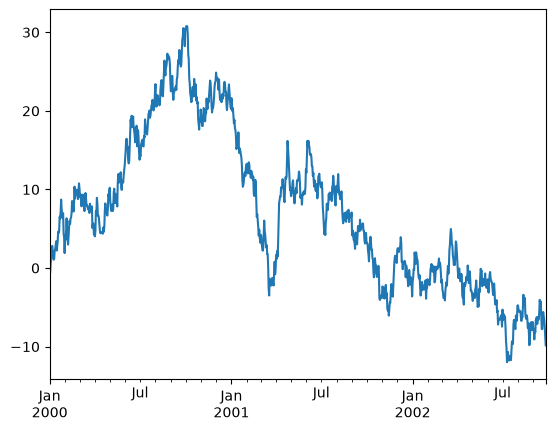

In [193]:
ts = pd.Series(np.random.randn(1000), index=pd.date_range("1/1/2000", periods=1000))

ts = ts.cumsum()

ts.plot();

**Note**

When using Jupyter, the plot will appear using plot(). Otherwise use matplotlib.pyplot.show to show it or matplotlib.pyplot.savefig to write it to a file.

plot() plots all columns:

<Figure size 640x480 with 0 Axes>

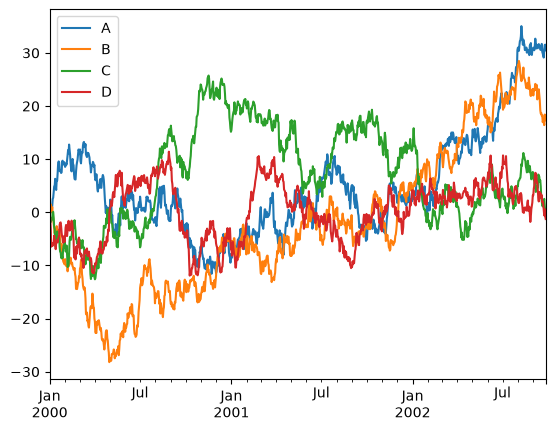

In [194]:
df = pd.DataFrame(
    np.random.randn(1000, 4), index=ts.index, columns=["A", "B", "C", "D"]
)


df = df.cumsum()

plt.figure();

df.plot();

plt.legend(loc='best');

# Importing and exporting data
See the IO Tools section.

# CSV
Writing to a csv file: using DataFrame.to_csv()

In [195]:
df = pd.DataFrame(np.random.randint(0, 5, (10, 5)))

df.to_csv("foo.csv")


Reading from a csv file: using read_csv()

In [196]:
pd.read_csv("foo.csv")


,Unnamed: 0,0,1,2,3,4
0,0,1,0,0,0,4
1,1,3,1,2,4,0
2,2,3,2,0,4,0
3,3,0,1,2,0,4
4,4,2,4,4,0,4
5,5,1,2,0,1,4
6,6,4,2,0,3,1
7,7,3,1,2,3,3
8,8,2,1,0,0,1
9,9,2,3,2,4,1


# Parquet
Writing to a Parquet file:

In [197]:
df.to_parquet("foo.parquet")


ImportError: Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - `Import pyarrow` failed. pyarrow is required for parquet support. Use pip or conda to install the pyarrow package.
 - `Import fastparquet` failed. fastparquet is required for parquet support. Use pip or conda to install the fastparquet package.

Reading from a Parquet file Store using read_parquet():

In [ ]:
pd.read_parquet("foo.parquet")


ImportError: Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - `Import pyarrow` failed. pyarrow is required for parquet support. Use pip or conda to install the pyarrow package.
 - `Import fastparquet` failed. fastparquet is required for parquet support. Use pip or conda to install the fastparquet package.

# Excel
Reading and writing to Excel.

Writing to an excel file using DataFrame.to_excel():

In [ ]:
df.to_excel("foo.xlsx", sheet_name="Sheet1")


Reading from an excel file using read_excel():

In [ ]:
pd.read_excel("foo.xlsx", "Sheet1", index_col=None, na_values=["NA"])


,Unnamed: 0,0,1,2,3,4
0,0,1,3,1,2,2
1,1,3,2,4,0,4
2,2,2,2,4,1,0
3,3,1,1,4,3,0
4,4,4,1,4,4,3
5,5,4,0,0,3,2
6,6,0,0,1,2,0
7,7,1,4,3,2,2
8,8,4,4,0,0,2
9,9,4,1,2,3,1


# Gotchas
If you are attempting to perform a boolean operation on a Series or DataFrame you might see an exception like:

In [ ]:
if pd.Series([False, True, False]):
     print("I was true")


ValueError: The truth value of a Series is ambiguous. Use a.empty, a.bool(), a.item(), a.any() or a.all().